<a href="https://colab.research.google.com/github/keyvanmahmoudi/Deep_Learning_Course/blob/main/sessions/Session16_gans_and_diffusion.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

# جلسهٔ ۱۶: مدل‌های مولد: GAN، Diffusion و پروژه پایانی

### اهداف این جلسه

- درک ایده بازی دونفره در شبکه‌های مولد تخاصمی (GAN) و تابع هزینه آن
- پیاده‌سازی و آموزش DCGAN روی Fashion-MNIST و آشنایی با مشکلات آموزش GAN
- درک ایده مدل‌های Diffusion: افزودن تدریجی نویز و یادگیری حذف آن
- پیاده‌سازی یک DDPM کامل روی داده دوبعدی و دیدن فرایند تولید گام‌به‌گام
- آشنایی با معیارهای پروژه پایانی دوره

> **نکتهٔ اجرا:** این نوت‌بوک روی GPU بسیار سریع‌تر اجرا می‌شود. در Colab از منوی `Runtime → Change runtime type` گزینهٔ **T4 GPU** را انتخاب کنید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۱. مدل‌های مولد (Generative Models)

مدل‌های طبقه‌بند **تمایزی (Discriminative)** هستند: $p(y \mid \mathbf{x})$ را یاد می‌گیرند. **مدل‌های مولد** توزیع خود داده، $p(\mathbf{x})$، را یاد می‌گیرند تا بتوانند **نمونه جدید** بسازند. در جلسه قبل VAE را دیدیم؛ نمونه‌هایش متنوع بودند اما تار. در این جلسه دو خانواده دیگر را می‌سازیم:

| خانواده | ایده | نقاط قوت | نقاط ضعف |
|---|---|---|---|
| VAE (جلسه ۱۵) | Encoder–Decoder با فضای نهان منظم | آموزش پایدار، فضای نهان معنادار | نمونه‌های تار |
| **GAN** | رقابت مولد و تمییزدهنده | نمونه‌های تیز، تولید سریع | آموزش ناپایدار، Mode Collapse |
| **Diffusion** | یادگیری حذف تدریجی نویز | کیفیت و تنوع بسیار بالا، آموزش پایدار | تولید کند (گام‌های زیاد) |
| Autoregressive (جلسه ۱۳) | تولید Token به Token | پایه مدل‌های زبانی بزرگ | تولید ترتیبی |

مدل‌هایی مثل Stable Diffusion، DALL·E 3 و Midjourney مبتنی بر Diffusion هستند و StyleGAN (چهره‌های واقع‌نما) مبتنی بر GAN.

</div>

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('device:', device)
torch.manual_seed(42)

device: cpu


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## ۲. شبکه‌های مولد تخاصمی (GAN)

**GAN** (Goodfellow et al., 2014) دو شبکه را در مقابل هم آموزش می‌دهد:

- **مولد (Generator) $G$:** از نویز تصادفی $\mathbf{z}\sim\mathcal{N}(\mathbf{0}, I)$ تصویر می‌سازد. مثل جاعل اسکناس.
- **تمییزدهنده (Discriminator) $D$:** یک طبقه‌بند دودویی که تشخیص می‌دهد تصویر واقعی است یا ساخته $G$. مثل پلیس.

$D$ تلاش می‌کند واقعی را از جعلی تشخیص دهد و $G$ تلاش می‌کند $D$ را فریب دهد. این یک **بازی کمینه‌بیشینه (Minimax)** است:

$$\min_G \max_D\ \mathbb{E}_{\mathbf{x}\sim p_{\text{data}}}\left[\log D(\mathbf{x})\right] + \mathbb{E}_{\mathbf{z}}\left[\log\left(1 - D(G(\mathbf{z}))\right)\right]$$

در عمل در هر گام دو به‌روزرسانی انجام می‌شود:

۱. **به‌روزرسانی $D$:** Binary Cross-Entropy با برچسب ۱ برای تصاویر واقعی و ۰ برای تصاویر ساخته‌شده.

۲. **به‌روزرسانی $G$:** تصاویر ساخته‌شده را با برچسب **۱** به $D$ می‌دهیم و فقط وزن‌های $G$ را به‌روز می‌کنیم. (این نسخه «Non-saturating» است که گرادیان قوی‌تری از کمینه کردن مستقیم $\log(1 - D(G(\mathbf{z})))$ می‌دهد.)

اگر بازی به تعادل برسد، $G$ توزیع داده را بازتولید می‌کند و $D$ در بهترین حالت فقط ۵۰٪ شانس دارد.

### DCGAN

**DCGAN** (Radford et al., 2016) قواعد معماری‌ای پیشنهاد کرد که آموزش GAN با CNN را پایدار کرد: Generator با `ConvTranspose2d` و BatchNorm و ReLU (خروجی Tanh)؛ Discriminator با کانولوشن Stride‌دار به‌جای Pooling و LeakyReLU؛ بهینه‌ساز Adam با $\beta_1 = 0.5$.

</div>

In [2]:
# images scaled to [-1, 1] to match the generator's tanh output
tf = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.5,), (0.5,))])
train_set = datasets.FashionMNIST('data', train=True, download=True, transform=tf)
loader = DataLoader(train_set, batch_size=128, shuffle=True, num_workers=2, drop_last=True)

Z_DIM = 64


class Generator(nn.Module):
    def __init__(self, z_dim=Z_DIM):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(z_dim, 128 * 7 * 7), nn.BatchNorm1d(128 * 7 * 7), nn.ReLU(),
            nn.Unflatten(1, (128, 7, 7)),
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),   # 7 -> 14
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1), nn.Tanh(),                        # 14 -> 28
        )

    def forward(self, z):
        return self.net(z)


class Discriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, stride=2, padding=1), nn.LeakyReLU(0.2),                         # 28 -> 14
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(0.2),  # 14 -> 7
            nn.Flatten(),
            nn.Linear(128 * 7 * 7, 1),                                                           # a logit
        )

    def forward(self, x):
        return self.net(x)


G, D = Generator().to(device), Discriminator().to(device)
print(f'G: {sum(p.numel() for p in G.parameters()):,} parameters | D: {sum(p.numel() for p in D.parameters()):,} parameters')

G: 552,513 parameters | D: 138,817 parameters


In [ ]:
GAN_EPOCHS = 15
opt_G = torch.optim.Adam(G.parameters(), lr=2e-4, betas=(0.5, 0.999))
opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
bce = nn.BCEWithLogitsLoss()
fixed_z = torch.randn(32, Z_DIM, device=device)            # same noise every epoch to watch progress
history, snapshots = {'D': [], 'G': [], 'D(x)': [], 'D(G(z))': []}, []

for epoch in range(1, GAN_EPOCHS + 1):
    G.train(); D.train()
    for real, _ in loader:
        real = real.to(device)
        b = real.size(0)
        ones, zeros = torch.ones(b, 1, device=device), torch.zeros(b, 1, device=device)

        # 1) discriminator: real -> 1, fake -> 0
        fake = G(torch.randn(b, Z_DIM, device=device))
        d_real, d_fake = D(real), D(fake.detach())          # detach: do not update G here
        loss_D = bce(d_real, ones) + bce(d_fake, zeros)
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()

        # 2) generator: make D output 1 for fakes
        loss_G = bce(D(fake), ones)
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()

    history['D'].append(loss_D.item()); history['G'].append(loss_G.item())
    history['D(x)'].append(torch.sigmoid(d_real).mean().item()); history['D(G(z))'].append(torch.sigmoid(d_fake).mean().item())
    G.eval()
    with torch.no_grad():
        snapshots.append(G(fixed_z).cpu())
    print(f"epoch {epoch:2d} | loss D {loss_D.item():.3f} | loss G {loss_G.item():.3f} | "
          f"D(real) {history['D(x)'][-1]:.2f} | D(fake) {history['D(G(z))'][-1]:.2f}")

In [ ]:
def show(images, nrow, title):
    images = images.clamp(-1, 1) * 0.5 + 0.5
    ncol = math.ceil(len(images) / nrow)
    fig, axes = plt.subplots(nrow, ncol, figsize=(1.2 * ncol, 1.25 * nrow))
    for ax in axes.flat:
        ax.axis('off')
    for ax, img in zip(axes.flat, images):
        ax.imshow(img[0], cmap='gray')
    plt.suptitle(title); plt.tight_layout(); plt.show()


for e in sorted({0, len(snapshots) // 2, len(snapshots) - 1}):
    show(snapshots[e][:16], 2, f'generator samples after epoch {e + 1}')

plt.figure(figsize=(9, 3.5))
plt.plot(history['D(x)'], 'o-', label='D(real)'); plt.plot(history['D(G(z))'], 's-', label='D(fake)')
plt.axhline(0.5, ls='--', color='gray'); plt.xlabel('epoch'); plt.legend(); plt.title('discriminator outputs')
plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

### چالش‌های آموزش GAN

- **عدم تعادل:** اگر $D$ خیلی قوی شود، گرادیان $G$ ضعیف می‌شود؛ اگر خیلی ضعیف باشد، راهنمای خوبی برای $G$ نیست. Loss در GAN مثل مسائل قبلی **کاهش یکنواخت ندارد** و معیار خوبی برای کیفیت نیست؛ باید نمونه‌ها را دید یا از معیارهایی مثل **FID** استفاده کرد.
- **Mode Collapse:** مولد فقط چند نوع نمونه تولید می‌کند که $D$ را فریب می‌دهند (مثلاً فقط کفش) و تنوع داده را پوشش نمی‌دهد.
- راه‌حل‌ها: معماری‌های پایدارتر (DCGAN، StyleGAN)، توابع هزینه دیگر (WGAN-GP)، Spectral Normalization و تنظیم دقیق نرخ‌های یادگیری.

## ۳. مدل‌های Diffusion

ایده **Denoising Diffusion Probabilistic Models (DDPM)** (Ho et al., 2020) از Denoising Autoencoder جلسه قبل الهام گرفته، اما با یک تفاوت مهم: به‌جای حذف نویز در یک گام، **در صدها گام کوچک**.

**فرایند رو به جلو (Forward Process)** که ثابت است و چیزی یاد نمی‌گیرد: در $T$ گام، کمی نویز گاوسی به داده اضافه می‌کنیم تا در پایان کاملاً به نویز خالص تبدیل شود. با یک زمان‌بندی نویز $\beta_1, \dots, \beta_T$ و $\bar{\alpha}_t = \prod_{s \le t}(1 - \beta_s)$، می‌توان مستقیماً به هر گام پرید:

$$\mathbf{x}_t = \sqrt{\bar{\alpha}_t}\,\mathbf{x}_0 + \sqrt{1 - \bar{\alpha}_t}\,\boldsymbol{\epsilon},\qquad \boldsymbol{\epsilon}\sim\mathcal{N}(\mathbf{0}, I)$$

**فرایند معکوس (Reverse Process)** که یاد گرفته می‌شود: یک شبکه $\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)$ آموزش می‌دهیم که **نویز اضافه‌شده را پیش‌بینی کند**. Loss بسیار ساده است:

$$\mathcal{L} = \mathbb{E}_{\mathbf{x}_0, t, \boldsymbol{\epsilon}}\left\|\boldsymbol{\epsilon} - \boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)\right\|^2$$

**تولید:** از نویز خالص $\mathbf{x}_T$ شروع می‌کنیم و در هر گام کمی از نویز پیش‌بینی‌شده را کم می‌کنیم (به‌علاوه کمی نویز تازه):

$$\mathbf{x}_{t-1} = \frac{1}{\sqrt{1-\beta_t}}\left(\mathbf{x}_t - \frac{\beta_t}{\sqrt{1-\bar{\alpha}_t}}\,\boldsymbol{\epsilon}_\theta(\mathbf{x}_t, t)\right) + \sqrt{\beta_t}\,\mathbf{z}$$

برای اینکه کل الگوریتم را روی CPU و در چند دقیقه ببینیم، DDPM را روی یک داده **دوبعدی** (شکل مارپیچ) پیاده می‌کنیم. الگوریتم دقیقاً همان است که برای تصاویر استفاده می‌شود؛ فقط شبکه $\boldsymbol{\epsilon}_\theta$ به‌جای یک U-Net، یک MLP کوچک است.

</div>

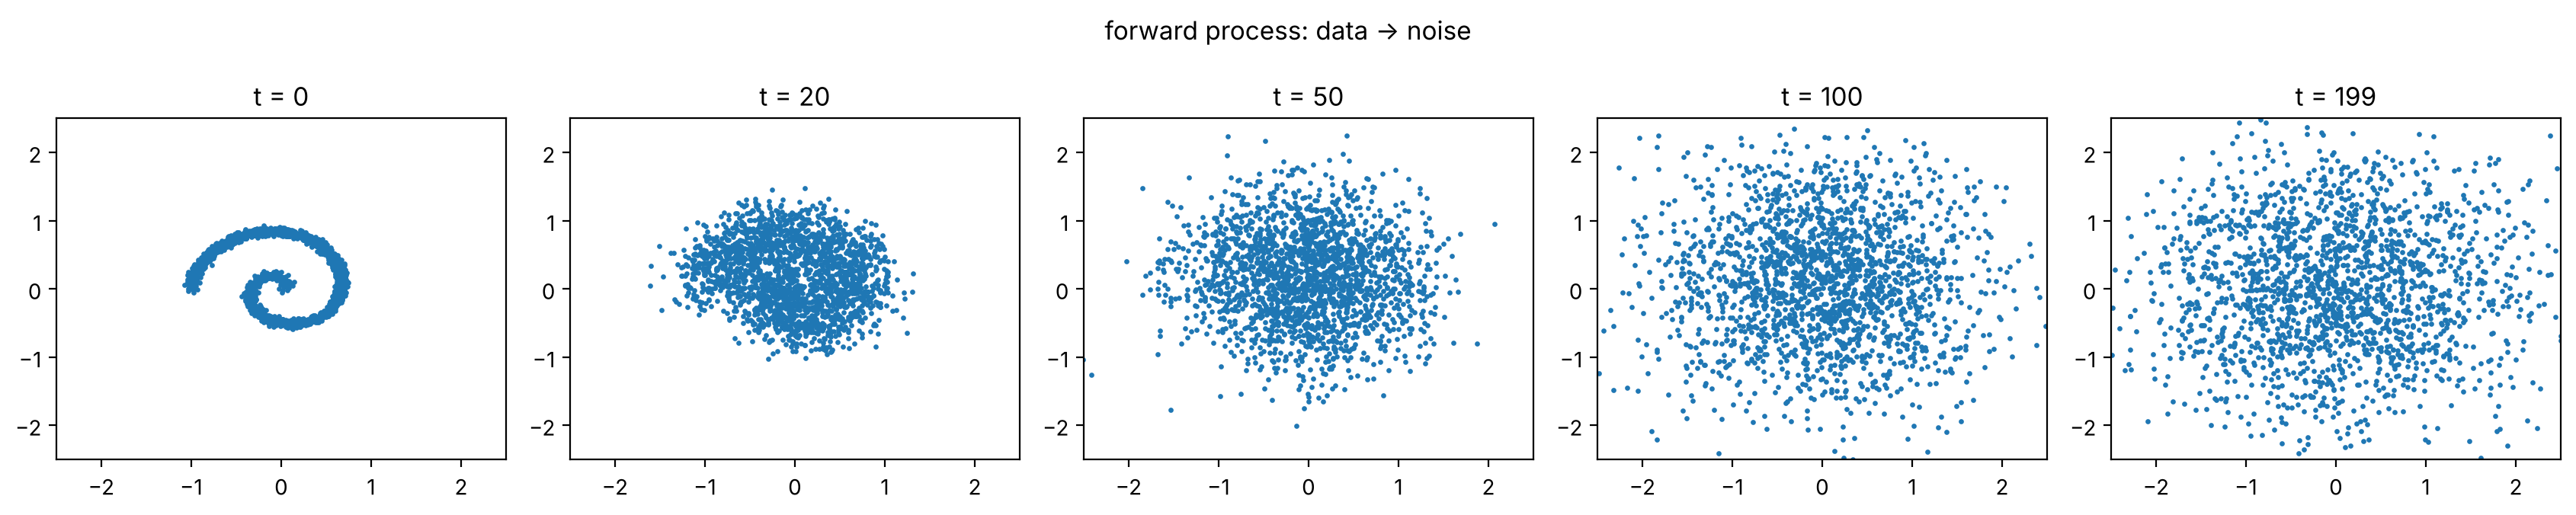

In [3]:
def make_spiral(n=10_000, noise=0.03):
    t = np.sqrt(np.random.rand(n)) * 3 * np.pi
    x = np.stack([t * np.cos(t), t * np.sin(t)], 1) / (3 * np.pi)
    return torch.tensor(x + noise * np.random.randn(n, 2), dtype=torch.float32)


data = make_spiral()
T_STEPS = 200
betas = torch.linspace(1e-4, 0.05, T_STEPS)
alphas = 1 - betas
alpha_bar = torch.cumprod(alphas, dim=0)


def q_sample(x0, t, eps):
    """Jump directly to step t of the forward (noising) process."""
    ab = alpha_bar[t].unsqueeze(1)
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps


fig, axes = plt.subplots(1, 5, figsize=(17, 3.4))
for ax, t in zip(axes, [0, 20, 50, 100, 199]):
    xt = q_sample(data[:2000], torch.full((2000,), t), torch.randn(2000, 2))
    ax.scatter(xt[:, 0], xt[:, 1], s=2); ax.set_title(f't = {t}'); ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
plt.suptitle('forward process: data -> noise'); plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

شبکه پیش‌بینی نویز باید بداند در کدام گام است. گام $t$ را مثل Positional Encoding جلسه ۱۳ به یک بردار سینوسی تبدیل می‌کنیم و کنار ورودی می‌گذاریم:

</div>

In [4]:
def time_embedding(t, dim=32):
    half = dim // 2
    freqs = torch.exp(-math.log(1000) * torch.arange(half, device=t.device) / half)
    angles = t.float().unsqueeze(1) * freqs.unsqueeze(0)
    return torch.cat([angles.sin(), angles.cos()], dim=1)


class NoisePredictor(nn.Module):
    def __init__(self, hidden=128, t_dim=32):
        super().__init__()
        self.t_dim = t_dim
        self.net = nn.Sequential(
            nn.Linear(2 + t_dim, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, hidden), nn.SiLU(),
            nn.Linear(hidden, 2),
        )

    def forward(self, x, t):
        return self.net(torch.cat([x, time_embedding(t, self.t_dim)], dim=1))


torch.manual_seed(0)
eps_model = NoisePredictor()
opt = torch.optim.Adam(eps_model.parameters(), lr=1e-3)
DIFF_STEPS = 6000
losses = []
for step in range(DIFF_STEPS):
    x0 = data[torch.randint(len(data), (256,))]
    t = torch.randint(0, T_STEPS, (256,))                  # a random step for every sample
    eps = torch.randn_like(x0)
    loss = F.mse_loss(eps_model(q_sample(x0, t, eps), t), eps)
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if step % 1000 == 0:
        print(f'step {step:5d} | loss {np.mean(losses[-200:]):.4f}')

step     0 | loss 1.0883


step  1000 | loss 0.2385


step  2000 | loss 0.2390


step  3000 | loss 0.2392


step  4000 | loss 0.2275


step  5000 | loss 0.2166


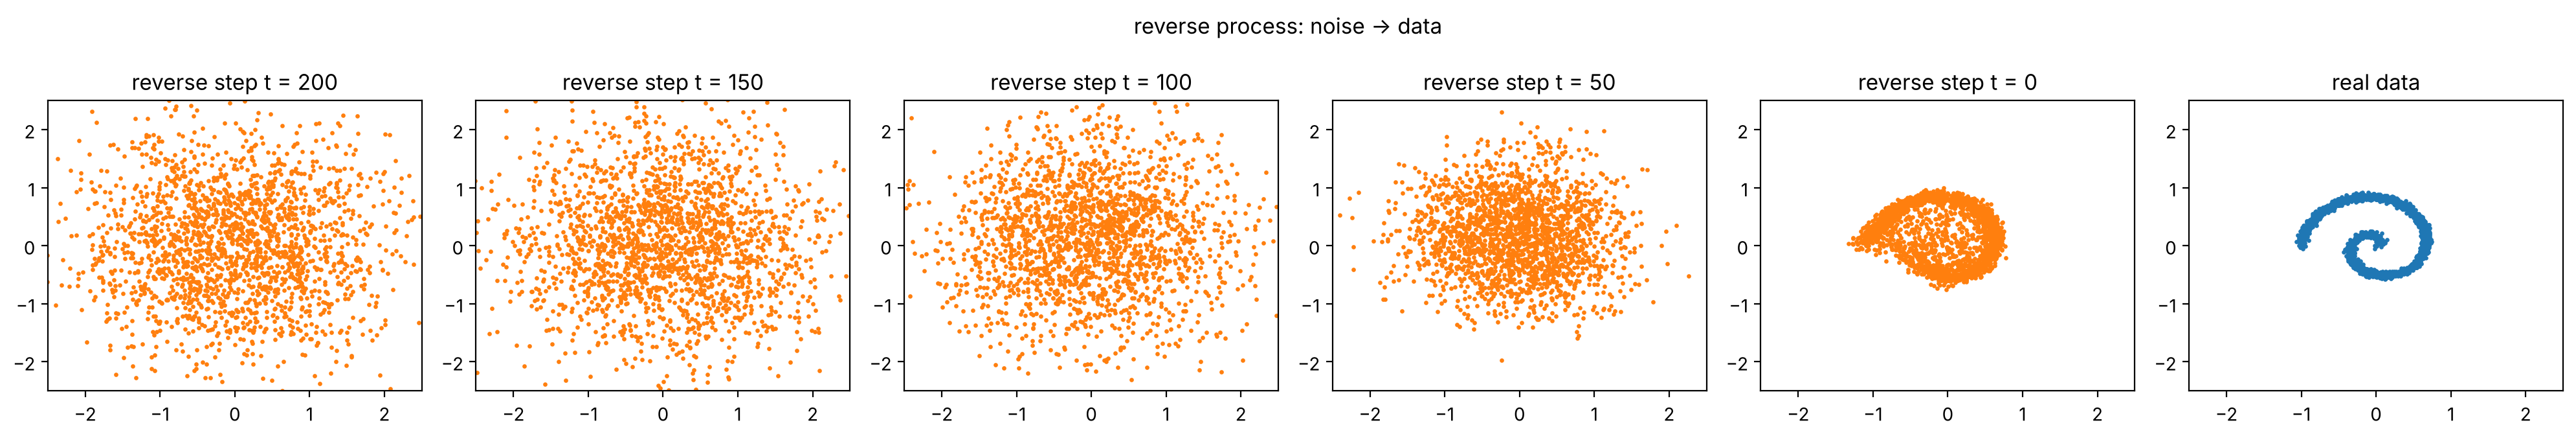

In [5]:
@torch.no_grad()
def sample(model, n=2000):
    x = torch.randn(n, 2)                                   # start from pure noise
    trajectory = {T_STEPS: x.clone()}
    for t in reversed(range(T_STEPS)):
        tt = torch.full((n,), t)
        eps = model(x, tt)
        x = (x - betas[t] / (1 - alpha_bar[t]).sqrt() * eps) / alphas[t].sqrt()
        if t > 0:
            x = x + betas[t].sqrt() * torch.randn_like(x)    # fresh noise except at the last step
        if t in (150, 100, 50, 0):
            trajectory[t] = x.clone()
    return trajectory


traj = sample(eps_model)
fig, axes = plt.subplots(1, 6, figsize=(20, 3.4))
for ax, t in zip(axes, [T_STEPS, 150, 100, 50, 0]):
    ax.scatter(traj[t][:, 0], traj[t][:, 1], s=2, color='C1'); ax.set_title(f'reverse step t = {t}')
axes[-1].scatter(data[:2000, 0], data[:2000, 1], s=2); axes[-1].set_title('real data')
for ax in axes:
    ax.set_xlim(-2.5, 2.5); ax.set_ylim(-2.5, 2.5)
plt.suptitle('reverse process: noise -> data'); plt.tight_layout(); plt.show()

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

از ابری از نقاط تصادفی، مدل گام‌به‌گام شکل کلی مارپیچ را بازسازی می‌کند. در این آموزش کوتاه، بازوی بیرونی به‌خوبی شکل می‌گیرد، اما بخش درونی و پیچ‌های نزدیک به هم هنوز تار و درهم‌اند؛ جزئیات ظریف‌تر به آموزش طولانی‌تر یا شبکهٔ بزرگ‌تر نیاز دارد. همین «اول شکل کلی، بعد جزئیات» در مدل‌های Diffusion تصویری هم دیده می‌شود. برای تصاویر، همین الگوریتم با یک **U-Net** (CNN با اتصال‌های میان‌بر بین Encoder و Decoder) به‌جای MLP و با $T = 1000$ گام اجرا می‌شود. Stable Diffusion سه تغییر مهم دارد: Diffusion در **فضای نهان یک Autoencoder** (جلسه ۱۵) انجام می‌شود، متن ورودی با یک Transformer کدگذاری و از طریق **Cross-Attention** (جلسه ۱۳) به U-Net داده می‌شود، و روش‌های نمونه‌برداری سریع‌تر (مثل DDIM) تعداد گام‌ها را به چند ده گام کاهش می‌دهند.

## ۴. مرور دوره: از نورون تا مدل‌های مولد

| بخش | جلسات | مفاهیم کلیدی |
|---|---|---|
| مبانی | ۱ تا ۴ | نورون، MLP، Backpropagation، PyTorch، حلقه آموزش |
| آموزش مؤثر | ۵ و ۶ | Adam، Scheduler، Initialization، Dropout، BatchNorm، Augmentation |
| بینایی ماشین | ۷ تا ۹ | CNN، ResNet، Transfer Learning |
| داده دنباله‌ای | ۱۰ تا ۱۴ | RNN، LSTM، Embedding، Attention، Transformer، BERT |
| مدل‌های مولد | ۱۵ و ۱۶ | Autoencoder، VAE، GAN، Diffusion |

## ۵. پروژه پایانی

هدف پروژه: حل یک مسئله واقعی از ابتدا تا انتها با روش‌های این دوره، به شکلی که قابل ارائه در رزومه و گیت‌هاب باشد.

**نمونه موضوع‌ها:**

- طبقه‌بندی تصاویر یک دامنه خاص با Transfer Learning (بیماری برگ گیاهان، تشخیص زباله‌های قابل بازیافت، غذاهای ایرانی)
- تحلیل احساس یا دسته‌بندی موضوعی متن فارسی با Fine-tuning مدل‌های BERT فارسی
- پیش‌بینی سری زمانی واقعی (مصرف انرژی، کیفیت هوا) با LSTM و مقایسه با خطوط مبنا
- تشخیص ناهنجاری در تراکنش‌ها با Autoencoder
- تولید متن یا شعر فارسی با یک Transformer کوچک

**آنچه باید تحویل داده شود:**

۱. یک نوتبوک تمیز و قابل اجرا از ابتدا تا انتها (روی Colab)، با توضیح هر مرحله.

۲. تعریف دقیق مسئله و معیار ارزیابی، و دلیل انتخاب آن معیار.

۳. حداقل یک **خط مبنای ساده** و مقایسه مدل نهایی با آن.

۴. تقسیم درست Train / Validation / Test و تنظیم ابرپارامترها فقط با Validation.

۵. تحلیل خطا: Confusion Matrix یا نمونه‌هایی که مدل اشتباه کرده و توضیح چرایی.

۶. یک README در گیت‌هاب که نتیجه را در چند خط و یک جدول خلاصه می‌کند.

**معیارهای ارزیابی پیشنهادی:** درستی روش‌شناسی (۳۰٪)، کیفیت کد و قابلیت بازتولید (۲۵٪)، تحلیل نتایج (۲۵٪)، ارائه (۲۰٪).

## جمع‌بندی

- GAN: رقابت مولد و تمییزدهنده؛ نمونه‌های تیز اما آموزش ناپایدار و خطر Mode Collapse.
- DCGAN: `ConvTranspose2d` و BatchNorm در مولد، LeakyReLU در تمییزدهنده، Adam با $\beta_1 = 0.5$.
- Diffusion: فرایند رو به جلوی ثابت (افزودن نویز) و فرایند معکوس آموخته‌شده (حذف نویز)؛ Loss برابر MSE بین نویز واقعی و پیش‌بینی‌شده.
- تولید در Diffusion گام‌به‌گام از نویز خالص است؛ مدل‌های متن‌به‌تصویر امروزی بر همین پایه‌اند.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

## تمرین‌ها

هر تمرین را در سلول کد زیر آن حل کنید. پاسخ پیشنهادی در پوشهٔ `solutions` آمده است.

۱. در GAN، نرخ یادگیری Discriminator را ۵ برابر کنید. چه اتفاقی برای $D(\text{fake})$ و کیفیت نمونه‌ها می‌افتد؟

۲. یک **Conditional GAN** بسازید: برچسب کلاس را (با یک `nn.Embedding`) به ورودی هر دو شبکه اضافه کنید تا بتوانید تولید یک کلاس خاص (مثلاً فقط کیف) را درخواست کنید.

۳. در DDPM دوبعدی، تعداد گام‌ها را ۲۰ و ۱۰۰۰ بگیرید (و `betas` را متناسب تنظیم کنید). کیفیت نمونه‌ها چه تغییری می‌کند؟

۴. DDPM را روی یک داده دوبعدی دیگر (مثلاً `make_moons` یا شکل یک حرف) آموزش دهید.

۵. موضوع پروژه پایانی خود را انتخاب کنید و یک صفحه پیشنهاد شامل مسئله، داده، معیار ارزیابی و خط مبنا بنویسید.

</div>

<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۱.** در GAN، نرخ یادگیری Discriminator را ۵ برابر کنید. چه اتفاقی برای $D(\text{fake})$ و کیفیت نمونه‌ها می‌افتد؟

</div>

In [6]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۲.** یک **Conditional GAN** بسازید: برچسب کلاس را (با یک `nn.Embedding`) به ورودی هر دو شبکه اضافه کنید تا بتوانید تولید یک کلاس خاص (مثلاً فقط کیف) را درخواست کنید.

</div>

In [7]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۳.** در DDPM دوبعدی، تعداد گام‌ها را ۲۰ و ۱۰۰۰ بگیرید (و `betas` را متناسب تنظیم کنید). کیفیت نمونه‌ها چه تغییری می‌کند؟

</div>

In [8]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۴.** DDPM را روی یک داده دوبعدی دیگر (مثلاً `make_moons` یا شکل یک حرف) آموزش دهید.

</div>

In [9]:
# پاسخ خود را اینجا بنویسید


<div dir="rtl" style="font-family: 'Vazirmatn FD', Vazirmatn, Tahoma, sans-serif;">

**تمرین ۵.** موضوع پروژه پایانی خود را انتخاب کنید و یک صفحه پیشنهاد شامل مسئله، داده، معیار ارزیابی و خط مبنا بنویسید.

</div>

In [10]:
# پاسخ خود را اینجا بنویسید
